**Name:** Vikrant Haral     
**Division:** E        
**Batch:** E1              
**Roll No.:** TY-319   
**PRN:** 202401040332

---

**Practical Assignment 6: K-Means Clustering**

---

**1. Import libraries:**

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

print("All libraries imported successfully!")


All libraries imported successfully!


**2. upload datasets**

In [ ]:

from google.colab import files

uploaded = files.upload()

print("Files uploaded successfully!")


Saving student_marks_60.csv to student_marks_60 (1).csv
Saving customers_7.csv to customers_7 (1).csv
Files uploaded successfully!


**Part A: K-means from Scratch**

Dataset: 7 customers with visits_per_month and spend_rs_1000.

We use K = 2 with starting centroids P1 and P4.

**A1. Euclidean Distance Function:**

Euclidean distance calculates the straight-line distance between two points.

Formula:
\[
d(P,Q)=\sqrt{(x_1-x_2)^2+(y_1-y_2)^2}
\]

**1. Load customer dataset:**

In [ ]:

customers = pd.read_csv("customers_7.csv")

print("Customer Dataset:")
display(customers)

print("\nDataset Shape:", customers.shape)

print("\nMissing Values:")
print(customers.isnull().sum())


Customer Dataset:


,customer,visits_per_month,spend_rs_1000
0,P1,1.0,1.0
1,P2,1.5,2.0
2,P3,3.0,4.0
3,P4,5.0,7.0
4,P5,3.5,5.0
5,P6,4.5,5.0
6,P7,3.5,4.5



Dataset Shape: (7, 3)

Missing Values:
customer            0
visits_per_month    0
spend_rs_1000       0
dtype: int64


**2. Define Euclidean distance**

In [ ]:

def euclidean(p, q):
    """Return the Euclidean distance between two points."""
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)

    return float(np.sqrt(np.sum((p - q) ** 2)))


# Quick check
print("Distance between P2 and P1:",
      round(euclidean([1.5, 2], [1, 1]), 2))


Distance between P2 and P1: 1.12


**A2 and A3. K-means Scratch Implementation:**

The K-means algorithm repeats two main steps:
1. Assign: Calculate the distance of each point from every centroid and assign it to the nearest cluster.
2. Update: Calculate the mean of the points in each cluster to obtain new centroids.
The process continues until the cluster assignments and centroids stop changing.

If two distances are equal, the point is assigned to the lower-numbered cluster (C1).

**1. Implement K-means from scratch:**

In [ ]:

def kmeans_scratch(X, initial_centroids, names=None,
                   max_iter=100, verbose=True):

    X = np.asarray(X, dtype=float)
    centroids = np.asarray(initial_centroids, dtype=float).copy()

    k = len(centroids)

    if names is None:
        names = [f"Point{i+1}" for i in range(len(X))]

    labels = None
    history = []

    for it in range(1, max_iter + 1):

        # ASSIGN STEP
        # Calculate distance of every point from every centroid
        dists = np.array([
            [euclidean(x, c) for c in centroids]
            for x in X
        ])

        # Assign points to nearest centroid
        # Ties go to the lower-numbered cluster
        new_labels = np.argmin(np.round(dists, 6), axis=1)

        if verbose:
            print(f"\nIteration {it}:")
            print("Current Centroids:")

            for j, c in enumerate(centroids):
                print(f"C{j+1} = ({c[0]:.3f}, {c[1]:.3f})")

            table = pd.DataFrame(
                np.round(dists, 2),
                columns=[f"Dist to C{j+1}" for j in range(k)],
                index=names
            )

            table["Assigned to"] = [
                f"C{l+1}" for l in new_labels
            ]

            display(table)

        # UPDATE STEP
        new_centroids = centroids.copy()

        for j in range(k):

            members = X[new_labels == j]

            if len(members) > 0:
                new_centroids[j] = members.mean(axis=0)

        history.append((
            centroids.copy(),
            dists.copy(),
            new_labels.copy()
        ))

        if verbose:
            print("Updated Centroids:")

            for j, c in enumerate(new_centroids):
                print(f"C{j+1} = ({c[0]:.3f}, {c[1]:.3f})")

        # STOP CONDITION
        if (labels is not None
            and np.array_equal(new_labels, labels)
            and np.allclose(new_centroids, centroids)):

            if verbose:
                print("\nNo point changed cluster.")
                print("Centroids stopped moving.")
                print("The algorithm stops.")

            centroids = new_centroids
            labels = new_labels
            break

        centroids = new_centroids
        labels = new_labels

    return labels, centroids, history


**2. Select features and initial centroids:**

In [ ]:

# Select numerical features
X_c = customers[
    ["visits_per_month", "spend_rs_1000"]
].values

# Customer names
names = customers["customer"].tolist()

# Initial centroids: P1 and P4
init = X_c[
    [names.index("P1"), names.index("P4")]
]

print("Initial Centroids:")
print(init)

# Execute K-means from scratch
labels_c, centroids_c, history_c = kmeans_scratch(
    X_c,
    init,
    names=names
)

print("\nFINAL RESULT")

for j in range(2):

    members = [
        n for n, l in zip(names, labels_c) if l == j
    ]

    print(
        f"C{j+1}: {members} "
        f"centroid = "
        f"({centroids_c[j][0]:.2f}, "
        f"{centroids_c[j][1]:.2f})"
    )


Initial Centroids:
[[1. 1.]
 [5. 7.]]

Iteration 1:
Current Centroids:
C1 = (1.000, 1.000)
C2 = (5.000, 7.000)


,Dist to C1,Dist to C2,Assigned to
P1,0.00,7.21,C1
P2,1.12,6.10,C1
P3,3.61,3.61,C1
P4,7.21,0.00,C2
P5,4.72,2.50,C2
P6,5.32,2.06,C2
P7,4.30,2.92,C2


Updated Centroids:
C1 = (1.833, 2.333)
C2 = (4.125, 5.375)

Iteration 2:
Current Centroids:
C1 = (1.833, 2.333)
C2 = (4.125, 5.375)


,Dist to C1,Dist to C2,Assigned to
P1,1.57,5.38,C1
P2,0.47,4.28,C1
P3,2.03,1.78,C2
P4,5.64,1.85,C2
P5,3.14,0.73,C2
P6,3.77,0.53,C2
P7,2.73,1.08,C2


Updated Centroids:
C1 = (1.250, 1.500)
C2 = (3.900, 5.100)

Iteration 3:
Current Centroids:
C1 = (1.250, 1.500)
C2 = (3.900, 5.100)


,Dist to C1,Dist to C2,Assigned to
P1,0.56,5.02,C1
P2,0.56,3.92,C1
P3,3.05,1.42,C2
P4,6.66,2.20,C2
P5,4.16,0.41,C2
P6,4.78,0.61,C2
P7,3.75,0.72,C2


Updated Centroids:
C1 = (1.250, 1.500)
C2 = (3.900, 5.100)

No point changed cluster.
Centroids stopped moving.
The algorithm stops.

FINAL RESULT
C1: ['P1', 'P2'] centroid = (1.25, 1.50)
C2: ['P3', 'P4', 'P5', 'P6', 'P7'] centroid = (3.90, 5.10)


**A4. Check Against Hand Calculation:**

The output is compared with the hand-calculated values given in Section 3 of the reference document.

**1. Verify distances and cluster assignments:**

In [ ]:

# Hand-calculated values from Section 3

hand = {
    1: {
        "dist": [
            [0.00, 7.21],
            [1.12, 6.10],
            [3.61, 3.61],
            [7.21, 0.00],
            [4.72, 2.50],
            [5.32, 2.06],
            [4.30, 2.92]
        ],
        "assign": ["C1", "C1", "C1", "C2", "C2", "C2", "C2"]
    },

    2: {
        "dist": [
            [1.57, 5.38],
            [0.47, 4.28],
            [2.03, 1.78],
            [5.64, 1.85],
            [3.14, 0.73],
            [3.77, 0.53],
            [2.73, 1.08]
        ],
        "assign": ["C1", "C1", "C2", "C2", "C2", "C2", "C2"]
    },

    3: {
        "dist": [
            [0.56, 5.02],
            [0.56, 3.92],
            [3.05, 1.42],
            [6.66, 2.20],
            [4.16, 0.41],
            [4.78, 0.61],
            [3.75, 0.72]
        ],
        "assign": ["C1", "C1", "C2", "C2", "C2", "C2", "C2"]
    }
}

all_ok = len(history_c) == 3

print("Number of iterations:",
      len(history_c),
      "| Hand calculation = 3")

for it, (cent, dists, lab) in enumerate(
    history_c, start=1
):

    dist_ok = np.allclose(
        np.round(dists, 2),
        np.array(hand[it]["dist"]),
        atol=0.011
    )

    assign_ok = [
        f"C{l+1}" for l in lab
    ] == hand[it]["assign"]

    all_ok = all_ok and dist_ok and assign_ok

    print(
        f"Iteration {it}: "
        f"distances match = {dist_ok}, "
        f"assignments match = {assign_ok}"
    )

final_ok = np.allclose(
    centroids_c,
    [[1.25, 1.50], [3.90, 5.10]]
)

print("\nFinal centroids match =", final_ok)

print(
    "\nOVERALL: Output matches the hand calculation ->",
    all_ok and final_ok
)


Number of iterations: 3 | Hand calculation = 3
Iteration 1: distances match = True, assignments match = True
Iteration 2: distances match = True, assignments match = True
Iteration 3: distances match = True, assignments match = True

Final centroids match = True

OVERALL: Output matches the hand calculation -> True


**A5. Plot Clusters with Centroids Marked as Red X:**

**1. Customer clustering visualization:**

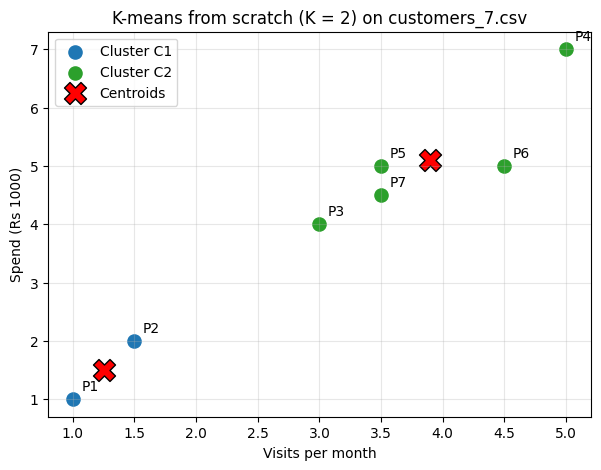

In [ ]:

colors = ["tab:blue", "tab:green"]

plt.figure(figsize=(7, 5))

for j in range(2):

    pts = X_c[labels_c == j]

    plt.scatter(
        pts[:, 0],
        pts[:, 1],
        s=90,
        c=colors[j],
        label=f"Cluster C{j+1}"
    )

# Label customer points
for n, (x, y) in zip(names, X_c):

    plt.annotate(
        n,
        (x, y),
        textcoords="offset points",
        xytext=(6, 6)
    )

# Plot centroids
plt.scatter(
    centroids_c[:, 0],
    centroids_c[:, 1],
    marker="X",
    s=250,
    c="red",
    edgecolors="black",
    label="Centroids"
)

plt.xlabel("Visits per month")
plt.ylabel("Spend (Rs 1000)")
plt.title("K-means from scratch (K = 2) on customers_7.csv")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Result of Part A:**

K-means converges in 3 iterations. C1 contains P1 and P2, representing occasional low-spending customers. C2 contains P3, P4, P5, P6 and P7, representing regular higher-spending customers. The final centroids match the hand calculation exactly.

**Part B: Scikit-learn and the Elbow Method**

In this part, we apply K-means using the scikit-learn library on the student marks dataset.

Dataset: student_marks_60.csv

Features:
- Theory marks
- Practical marks
We will test K values from 1 to 8 and use WCSS to identify the optimal number of clusters.
B1. Run KMeans for K = 1 to 8 and Record Inertia (WCSS)

**1. Load student dataset**

In [ ]:

df = pd.read_csv("student_marks_60.csv")

X = df[
    ["theory_marks", "practical_marks"]
].values

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())


Dataset Shape: (60, 3)

First 5 Records:


,roll_no,theory_marks,practical_marks
0,S01,36.9,40.1
1,S02,35.1,48.9
2,S03,80.2,86.3
3,S04,41.8,38.8
4,S05,89.2,79.4



Missing Values:
roll_no            0
theory_marks       0
practical_marks    0
dtype: int64

Statistical Summary:


,theory_marks,practical_marks
count,60.000000,60.000000
mean,62.198333,66.573333
std,18.191798,18.051760
min,28.300000,37.200000
25%,44.300000,48.575000
50%,61.500000,69.300000
75%,80.725000,83.800000
max,93.000000,94.500000


**2. Calculate WCSS for K = 1 to 8**

WCSS (Within-Cluster Sum of Squares) measures the sum of squared distances between each data point and its assigned cluster centroid.

Lower WCSS indicates more compact clusters.

In [ ]:

k_values = range(1, 9)
wcss = []

for k in k_values:

    km = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    km.fit(X)

    wcss.append(km.inertia_)

# Display WCSS table
wcss_table = pd.DataFrame({
    "K": list(k_values),
    "WCSS (inertia_)": np.round(wcss, 1)
})

wcss_table["Drop from previous K"] = (
    wcss_table["WCSS (inertia_)"].diff().round(1)
)

display(wcss_table)


,K,WCSS (inertia_),Drop from previous K
0,1,38751.6,NaN
1,2,10212.1,-28539.5
2,3,2204.7,-8007.4
3,4,1765.6,-439.1
4,5,1387.8,-377.8
5,6,1153.1,-234.7
6,7,1015.2,-137.9
7,8,876.1,-139.1


**B2. Elbow Curve and Best K:**

The elbow method helps identify the optimal number of clusters by observing the reduction in WCSS.

The best K is selected at the point where the curve starts flattening.

**1. Plot the elbow curve:**

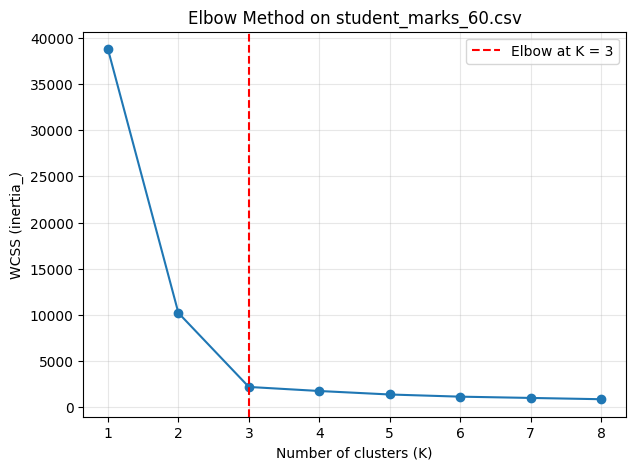

In [ ]:

plt.figure(figsize=(7, 5))

plt.plot(
    list(k_values),
    wcss,
    marker="o"
)

plt.axvline(
    3,
    color="red",
    linestyle="--",
    label="Elbow at K = 3"
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS (inertia_)")

plt.title("Elbow Method on student_marks_60.csv")

plt.xticks(list(k_values))
plt.legend()
plt.grid(alpha=0.3)

plt.show()


Best K = 3

**Reason:**

WCSS drops significantly from K = 1 to K = 2 to K = 3 (approximately 38,752 to 10,212 to 2,205). After K = 3, each additional cluster only reduces WCSS slightly. Therefore, the curve starts flattening and forms an elbow at K = 3.

We select K = 3 because it provides a good balance between cluster compactness and model complexity.

**B3. Final Model with K = 3: Clusters and Centroids**

Now we train the final K-means model using the optimal K value.

**1. Fit final K-means model:**

In [ ]:

best_k = 3

final_model = KMeans(
    n_clusters=best_k,
    n_init=10,
    random_state=42
)

# Fit model and predict clusters
df["cluster"] = final_model.fit_predict(X)

# Get cluster centroids
centers = final_model.cluster_centers_

print("Final Model: K-Means with K = 3")

print("\nCluster Centroids:")

for j, center in enumerate(centers):

    print(
        f"Cluster {j}: "
        f"({center[0]:.2f}, {center[1]:.2f})"
    )

print("\nStudent Cluster Assignments:")
print("First 10 Student Cluster Assignments:")
display(df.head(10))


Final Model: K-Means with K = 3

Cluster Centroids:
Cluster 0: (84.13, 86.56)
Cluster 1: (41.42, 44.05)
Cluster 2: (61.05, 69.12)

Student Cluster Assignments:
First 10 Student Cluster Assignments:


,roll_no,theory_marks,practical_marks,cluster,batch
0,S01,36.9,40.1,1,Remedial batch
1,S02,35.1,48.9,1,Remedial batch
2,S03,80.2,86.3,0,Advanced batch
3,S04,41.8,38.8,1,Remedial batch
4,S05,89.2,79.4,0,Advanced batch
5,S06,62.9,72.1,2,Regular batch
6,S07,37.4,42.9,1,Remedial batch
7,S08,56.5,71.0,2,Regular batch
8,S09,38.9,40.9,1,Remedial batch
9,S10,85.4,85.4,0,Advanced batch


**2. Plot student clusters and centroids:**

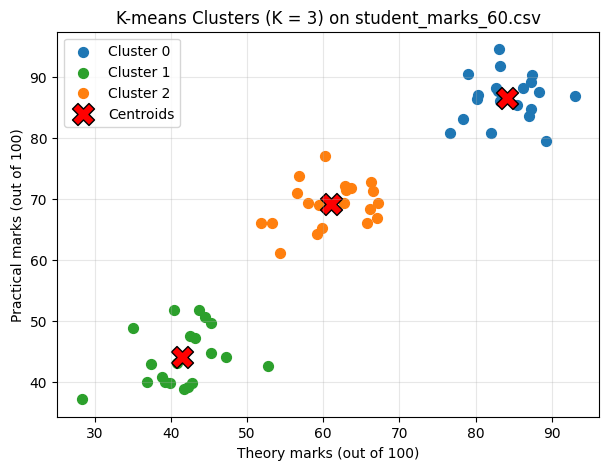

In [ ]:

plt.figure(figsize=(7, 5))

palette = [
    "tab:blue",
    "tab:green",
    "tab:orange"
]

for j in range(best_k):

    pts = X[df["cluster"] == j]

    plt.scatter(
        pts[:, 0],
        pts[:, 1],
        s=50,
        c=palette[j],
        label=f"Cluster {j}"
    )

# Plot centroids
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    c="red",
    edgecolors="black",
    label="Centroids"
)

plt.xlabel("Theory marks (out of 100)")
plt.ylabel("Practical marks (out of 100)")

plt.title("K-means Clusters (K = 3) on student_marks_60.csv")

plt.legend()
plt.grid(alpha=0.3)

plt.show()


**Result of Part B:**

The elbow method identifies K = 3 as the optimal number of clusters. The final K-means model successfully groups the 60 students into three clusters based on their theory and practical marks.

**Part C: Interpretation**

In this part, we interpret the clusters obtained from the final K-means model.

**C1. Size and Average Marks of Each Cluster:**

We calculate:
- Number of students in each cluster.
- Average theory marks.
- Average practical marks.

**1. Calculate cluster statistics:**

In [ ]:

summary = (
    df.groupby("cluster")
    .agg(
        students=("roll_no", "count"),
        avg_theory=("theory_marks", "mean"),
        avg_practical=("practical_marks", "mean")
    )
    .round(2)
)

# Print cluster information
for c, row in summary.iterrows():

    print(
        f"Cluster {c}: "
        f"{int(row['students'])} students | "
        f"average theory = {row['avg_theory']:.2f} | "
        f"average practical = {row['avg_practical']:.2f}"
    )

print("\nCluster Summary:")
display(summary)


Cluster 0: 20 students | average theory = 84.13 | average practical = 86.56
Cluster 1: 20 students | average theory = 41.42 | average practical = 44.04
Cluster 2: 20 students | average theory = 61.04 | average practical = 69.12

Cluster Summary:


,students,avg_theory,avg_practical
cluster,,,
0,20,84.13,86.56
1,20,41.42,44.04
2,20,61.04,69.12


**C2. Meaningful Cluster Names:**

Based on the average theory and practical marks, we assign meaningful names to the clusters.
- Remedial Batch: Students with comparatively low marks.
- Regular Batch: Students with moderate marks.
- Advanced Batch: Students with high marks.

**1. Assign cluster names:**

In [ ]:

# Rank clusters by their overall average marks
order = (
    summary["avg_theory"] +
    summary["avg_practical"]
).sort_values().index.tolist()

# Assign meaningful names
batch_names = {
    order[0]: "Remedial batch",
    order[1]: "Regular batch",
    order[2]: "Advanced batch"
}

# Add batch names to summary and dataset
summary["batch_name"] = summary.index.map(batch_names)

df["batch"] = df["cluster"].map(batch_names)

# Interpretation of each batch
meaning = {
    "Remedial batch":
        "Low marks in both theory and practicals: "
        "needs extra classes and practice sessions.",

    "Regular batch":
        "Average marks in both: follows the normal "
        "teaching plan.",

    "Advanced batch":
        "High marks in both: can be given advanced "
        "or challenging work."
}

# Display interpretation
for c in order:

    name = batch_names[c]

    print(
        f"Cluster {c} -> {name} "
        f"({int(summary.loc[c, 'students'])} students, "
        f"theory {summary.loc[c, 'avg_theory']:.1f}, "
        f"practical {summary.loc[c, 'avg_practical']:.1f}): "
        f"{meaning[name]}"
    )

print("\nFinal Batch Summary:")

display(
    summary[
        ["batch_name", "students",
         "avg_theory", "avg_practical"]
    ]
)


Cluster 1 -> Remedial batch (20 students, theory 41.4, practical 44.0): Low marks in both theory and practicals: needs extra classes and practice sessions.
Cluster 2 -> Regular batch (20 students, theory 61.0, practical 69.1): Average marks in both: follows the normal teaching plan.
Cluster 0 -> Advanced batch (20 students, theory 84.1, practical 86.6): High marks in both: can be given advanced or challenging work.

Final Batch Summary:


,batch_name,students,avg_theory,avg_practical
cluster,,,,
0,Advanced batch,20,84.13,86.56
1,Remedial batch,20,41.42,44.04
2,Regular batch,20,61.04,69.12


**2. Final plot with batch names:**

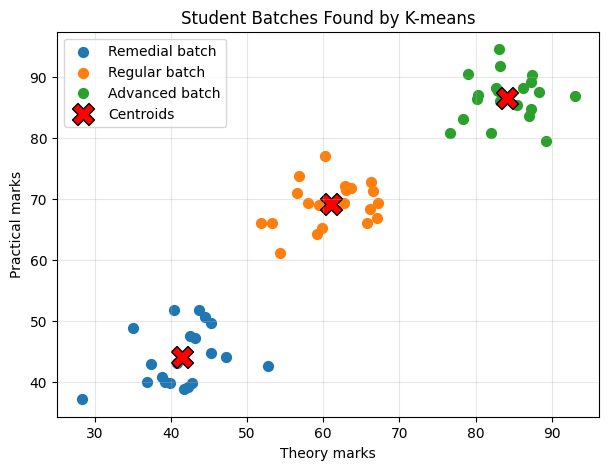

In [ ]:

plt.figure(figsize=(7, 5))

for c in order:

    pts = X[df["cluster"] == c]

    plt.scatter(
        pts[:, 0],
        pts[:, 1],
        s=50,
        label=batch_names[c]
    )

# Plot centroids
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    c="red",
    edgecolors="black",
    label="Centroids"
)

plt.xlabel("Theory marks")
plt.ylabel("Practical marks")

plt.title("Student Batches Found by K-means")

plt.legend()
plt.grid(alpha=0.3)

plt.show()


**C3. Predict the Group of a New Student with Marks (70, 72):**

We use the trained K-means model to predict the cluster of a new student whose:
- Theory marks = 70
- Practical marks = 72

**1. Predict the new student's cluster**

In [ ]:

# New student marks
new_student = np.array([[70, 72]])

# Predict cluster
pred = int(final_model.predict(new_student)[0])

# Calculate distance to each centroid
dist_to_centres = [
    euclidean(new_student[0], c)
    for c in centers
]

print("Distance of (70, 72) to each centroid:\n")

for j, d in enumerate(dist_to_centres):

    print(
        f"Cluster {j} ({batch_names[j]}): "
        f"centroid = "
        f"({centers[j][0]:.2f}, {centers[j][1]:.2f}), "
        f"distance = {d:.2f}"
    )

print(
    f"\nPredicted cluster for the new student (70, 72): "
    f"Cluster {pred} -> {batch_names[pred]}"
)


Distance of (70, 72) to each centroid:

Cluster 0 (Advanced batch): centroid = (84.13, 86.56), distance = 20.29
Cluster 1 (Remedial batch): centroid = (41.42, 44.05), distance = 39.98
Cluster 2 (Regular batch): centroid = (61.05, 69.12), distance = 9.41

Predicted cluster for the new student (70, 72): Cluster 2 -> Regular batch


**Expected prediction:**

The student with marks (70, 72) is expected to belong to the Regular Batch because the student's marks are closest to the Regular Batch centroid.

**Final Conclusion:**

In [ ]:

print("=" * 55)
print("CONCLUSION")
print("=" * 55)

print("""
1. K-means clustering was successfully implemented
   from scratch using Euclidean distance.

2. Seven customers were grouped into two clusters
   based on their visits and spending patterns.

3. The algorithm converged in three iterations and
   produced the expected final centroids.

4. Scikit-learn K-means was applied to 60 student
   records using theory and practical marks.

5. The elbow method identified K = 3 as the
   optimal number of clusters.

6. Students were classified into Remedial,
   Regular and Advanced batches.

7. A new student with marks (70, 72) was
   classified into the Regular Batch.

Thus, K-means clustering helps identify meaningful
groups in customer and student datasets.
""")


CONCLUSION

1. K-means clustering was successfully implemented
   from scratch using Euclidean distance.

2. Seven customers were grouped into two clusters
   based on their visits and spending patterns.

3. The algorithm converged in three iterations and
   produced the expected final centroids.

4. Scikit-learn K-means was applied to 60 student
   records using theory and practical marks.

5. The elbow method identified K = 3 as the
   optimal number of clusters.

6. Students were classified into Remedial,
   Regular and Advanced batches.

7. A new student with marks (70, 72) was
   classified into the Regular Batch.

Thus, K-means clustering helps identify meaningful
groups in customer and student datasets.

